# Problema 3 – Classificação de Qualidade de Vinhos Utilizando k-NN

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

## 1. Preparação dos dados:

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=";")
df["classe"] = pd.cut(
    df["quality"], bins=[-1, 5, 7, 10], labels=["ruim", "medio", "bom"]
)
print(df["classe"].value_counts())
df.head()

classe
medio    837
ruim     744
bom       18
Name: count, dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,classe
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,ruim
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,ruim
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,ruim
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,medio
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,ruim


## 2. Divisão treino/teste

In [ ]:
X = df.drop(columns=["quality", "classe"])
y = df["classe"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
valores_k = [1, 3, 5, 7, 9, 11, 13, 15, 17]
resultados = []

for k in valores_k:
    modelo = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )
    scores = cross_val_score(modelo, X_treino, y_treino, cv=cv, scoring="accuracy")
    resultados.append(scores.mean())
    print(f"k={k}: acurácia média={scores.mean():.4f}")

k=1: acurácia média=0.7248
k=2: acurácia média=0.6739
k=3: acurácia média=0.6888
k=4: acurácia média=0.6865
k=5: acurácia média=0.7013
k=7: acurácia média=0.7060
k=9: acurácia média=0.7170
k=11: acurácia média=0.7115
k=13: acurácia média=0.7146
k=15: acurácia média=0.7193
k=17: acurácia média=0.7099


## 3. Treinamento e escolha do k

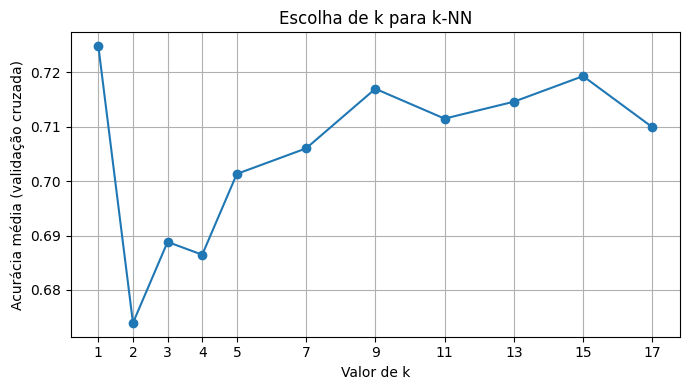

Melhor k pela validação cruzada: 1


In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(valores_k, resultados, marker="o")
plt.xlabel("Valor de k")
plt.ylabel("Acurácia média (validação cruzada)")
plt.title("Escolha de k para k-NN")
plt.xticks(valores_k)
plt.grid(True)
plt.tight_layout()
plt.show()

melhor_k = valores_k[int(np.argmax(resultados))]
print("Melhor k pela validação cruzada:", melhor_k)

## 4. Avaliar do model

Acurácia no teste: 0.7656
              precision    recall  f1-score   support

         bom       0.00      0.00      0.00         4
       medio       0.76      0.80      0.78       167
        ruim       0.77      0.75      0.76       149

    accuracy                           0.77       320
   macro avg       0.51      0.52      0.51       320
weighted avg       0.76      0.77      0.76       320



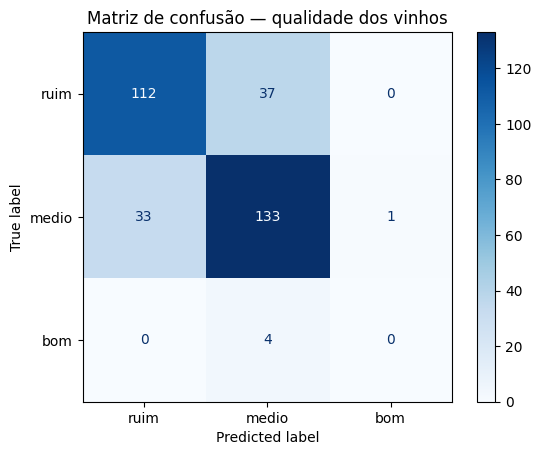

In [ ]:
modelo_final = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=melhor_k)
)
modelo_final.fit(X_treino, y_treino)
previsoes = modelo_final.predict(X_teste)

print(f"Acurácia no teste: {accuracy_score(y_teste, previsoes):.4f}")
print(classification_report(y_teste, previsoes, zero_division=0))

ordem = ["ruim", "medio", "bom"]
ConfusionMatrixDisplay.from_predictions(
    y_teste, previsoes, labels=ordem, display_labels=ordem, cmap="Blues"
)
plt.title("Matriz de confusão — qualidade dos vinhos")
plt.show()